In [1]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from src import Questions
import matplotlib.patches as mpatches


plt.rcParams.update({'font.size': 17})

In [2]:
# creating a dataframe of all of the annotator profiles
questions = Questions().get_questions()
SCORED_ANNOTATOR_DIR = "annotation_artefacts/final_annotator_objects"
RUN_NAME = "gpt_4o"
os.makedirs(SCORED_ANNOTATOR_DIR, exist_ok=True)

In [3]:
# making a raw scores (both characteristic and downstream) for each annotator
all_tasktype_df = {}

task_types = ['mt_and_summarization', 'syntaxes', 'knowledge_and_reasoning', 'semantics', 'qa_extraction']
for tt in task_types:
    downstream_score_df = []
    for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
        annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
        with open(annotator_filepath, "r") as  ao:
            annotator_object = json.load(ao)
        
        downstream_scores = {}
        for question_key, values in annotator_object["answers"].items():
            if values["answer"] == None or questions[question_key]["question_type"] != tt:
                continue
            for qid, score_s in values["downstream_scores"][RUN_NAME].items():
                postfix = questions[question_key]["metrics"][0] # first metric entry is by convention default
                matching_keys = [k for k in score_s if k.endswith(f"{postfix}_score")]
                if not matching_keys:
                    raise ValueError(f"No key ends with '{postfix}' for qid {qid}")
                correct_key = matching_keys[0]
                downstream_scores[f"{qid}-sentence_type"] = values["sentence_type"]
                downstream_scores[f"{qid}-sentence_length"] = values["sentence_length"]
                downstream_scores[f"{qid}-sentence_grammaticality"] = values["grammaticality"]
                downstream_scores[correct_key] = score_s[correct_key]

        downstream_score_df.append({
            "id" : annotator_object["id"],
            **downstream_scores,
        })
    all_tasktype_df[tt] = pd.DataFrame(downstream_score_df)

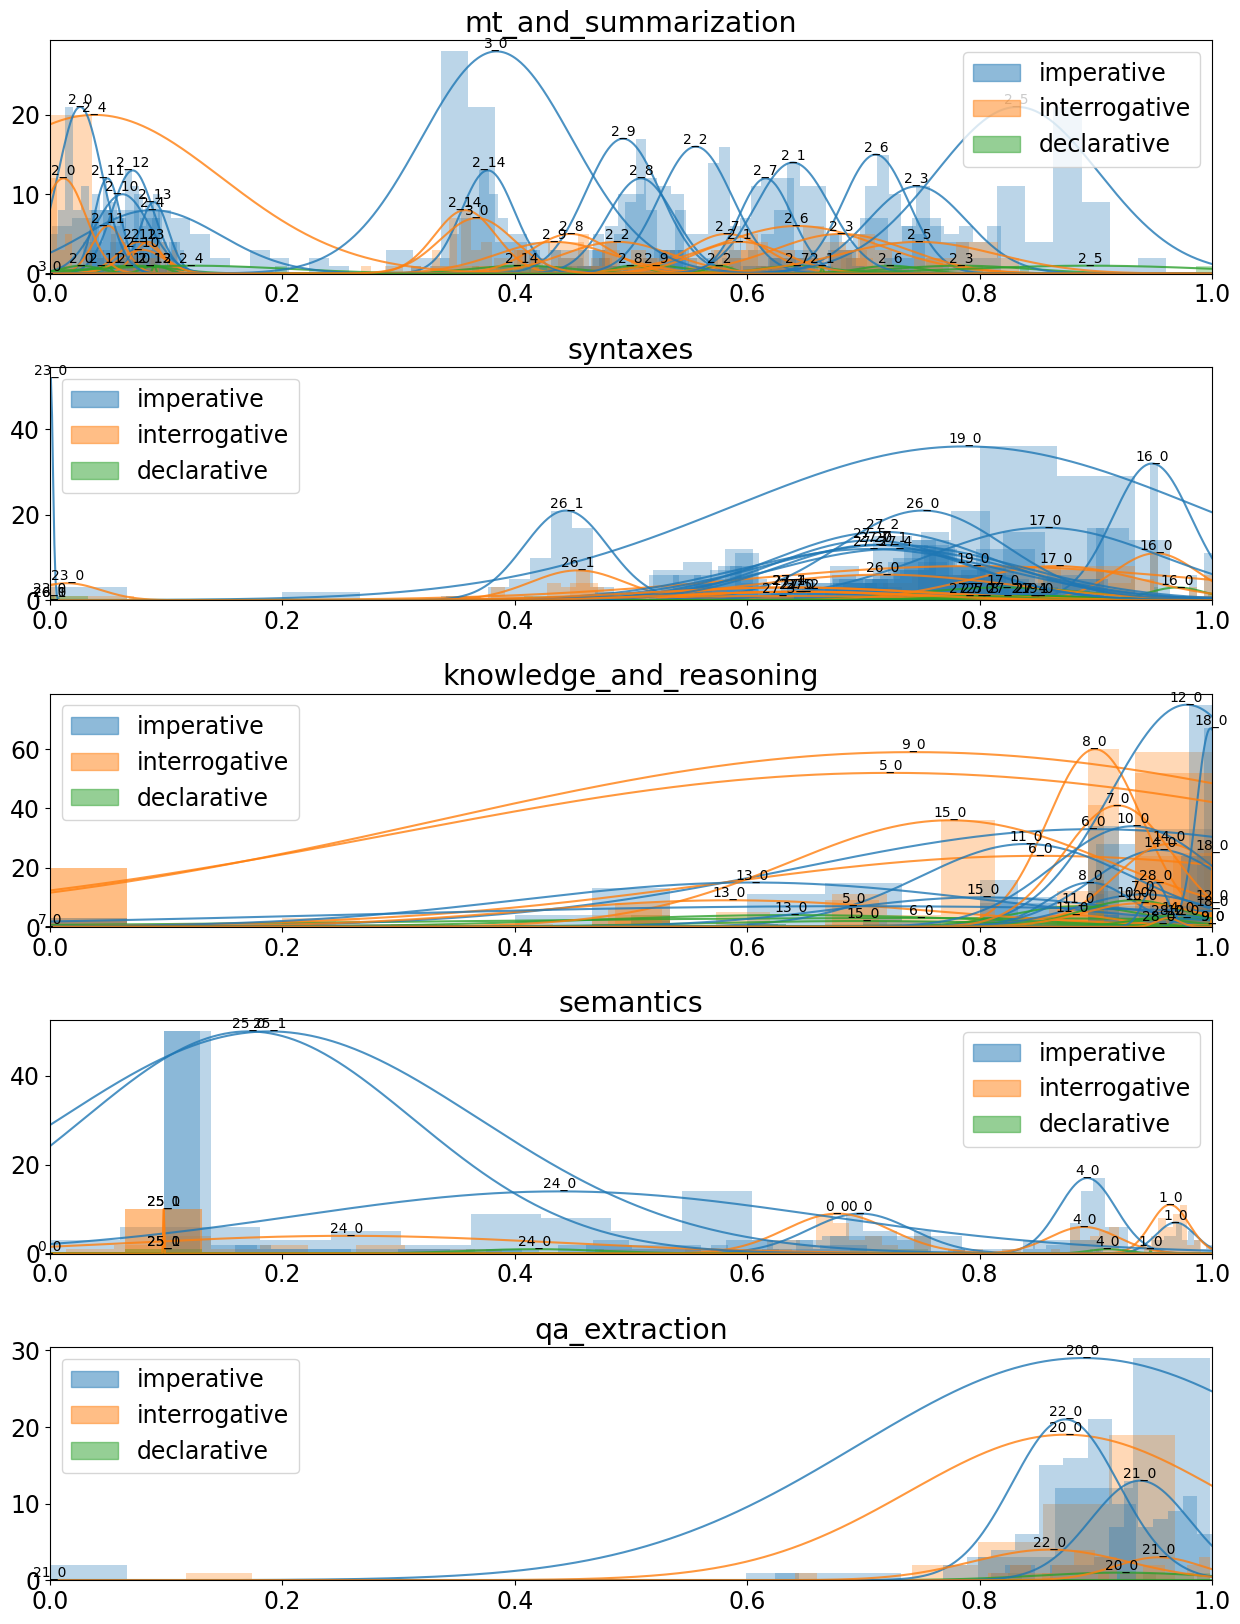

In [4]:
def collect_all_numbers(d):
    all_nums = []
    def recurse(x):
        if isinstance(x, dict):
            for v in x.values():
                recurse(v)
        elif isinstance(x, list):
            all_nums.extend(x)
    recurse(d)
    return all_nums

def normalize_nested_dict(d, min_val, max_val):
    def recurse(x):
        if isinstance(x, dict):
            for k, v in x.items():
                x[k] = recurse(v)
        elif isinstance(x, list):
            return [(i - min_val) / (max_val - min_val) if max_val != min_val else 0 for i in x]
        return x
    return recurse(d)

# propmt_sentence_type
characteristics_column = 0
task_group_histogram_data = {}
for tt in task_types:
    taskdf = all_tasktype_df[tt].drop(columns=['id'])
    cols = list(taskdf.columns)
    
    group_tasks_histogram_data = {}
    for i in range(0, len(cols), 4):
        chunk = cols[i:i+4]
        label_scores = {}
        for group_name, group_df in taskdf.groupby(chunk[characteristics_column]):
            label_scores[group_name] = group_df[chunk[-1]].tolist()
        
        task_code = chunk[0].split("-")[0]
        group_tasks_histogram_data[task_code] = label_scores

    all_nums = collect_all_numbers(group_tasks_histogram_data)
    min_val = min(all_nums)
    max_val = max(all_nums)
    task_group_histogram_data[tt] = normalize_nested_dict(group_tasks_histogram_data, min_val, max_val)

# print(json.dumps(task_group_histogram_data, indent=4))
# Plot all as overlapping histograms
colors = {
    "imperative" : '#1f77b4',
    "interrogative" : '#ff7f0e',
    "declarative" : '#2ca02c',
}

fig, axes = plt.subplots(len(all_tasktype_df.keys()), 1, figsize=(15, 4 * len(all_tasktype_df.keys())))
plt.subplots_adjust(hspace=0.4)  # Increase for more gap
# fig.xlim(0, 1)

for ax, (group_name, group_hist_data) in zip(axes, task_group_histogram_data.items()):
    ax.set_xlim(0, 1)
    ax.set_title(group_name)
    for qdi, classifications in group_hist_data.items():
        for label, score_list in classifications.items():
            counts, bin_edges, _ = ax.hist(score_list, bins=15, alpha=0.3, label=f'Data {i}', color=colors[label])
            
            mu, std = np.mean(score_list), np.std(score_list)
            if std == 0:
                std = 1e-6
            x = np.linspace(0, 1, 1000)
            p = norm.pdf(x, mu, std)
            p_max = np.max(p)
            
            if p_max == 0:
                scale = 1  # or skip plotting the curve
            else:
                scale = max(counts) / p_max

            # Get the current color used for the histogram
            ax.plot(x, p * scale, color=colors[label], alpha=0.8)

            peak_x = x[np.argmax(p)]
            peak_y = max(p) * scale
            ax.text(peak_x, peak_y, qdi, ha='center', va='bottom', fontsize=10)

            legend_patches = [mpatches.Patch(color=col, label=label, alpha=0.5) for label, col in colors.items()]
            ax.legend(handles=legend_patches)
    # break


In [5]:
all_tasktype_df["mt_and_summarization"]

,id,2_14-sentence_type,2_14-sentence_length,2_14-sentence_grammaticality,Machine Translation-hau_Latn-2_14-bleu_score,2_13-sentence_type,2_13-sentence_length,2_13-sentence_grammaticality,Machine Translation-amh_Ethi-2_13-bleu_score,2_12-sentence_type,...,2_0-sentence_grammaticality,Machine Translation-zho_Hans-2_0-bleu_score,2_5-sentence_type,2_5-sentence_length,2_5-sentence_grammaticality,Machine Translation-ind_Latn-2_5-bleu_score,3_0-sentence_type,3_0-sentence_length,3_0-sentence_grammaticality,Dialogue Summarization-3_0-rouge_score
0,34,imperative,4.0,correct,17.570766,imperative,4.0,correct,4.112560,imperative,...,correct,1.732917,imperative,4.0,correct,39.747898,imperative,4.0,correct,26.237550
1,63,imperative,5.0,correct,20.141160,imperative,5.0,correct,4.150831,imperative,...,correct,4.001363,imperative,5.0,correct,44.156976,imperative,3.0,correct,17.483873
2,75,imperative,5.0,correct,19.109176,imperative,5.0,correct,4.017584,imperative,...,correct,0.873292,imperative,5.0,correct,42.963829,imperative,10.0,correct,18.329531
3,22,interrogative,9.0,correct,18.192568,interrogative,9.0,correct,3.745281,interrogative,...,correct,0.119907,interrogative,9.0,correct,33.868834,interrogative,10.0,correct,18.276441
4,59,interrogative,4.0,correct,17.473719,interrogative,4.0,correct,5.105603,interrogative,...,correct,0.812096,interrogative,4.0,correct,39.498972,interrogative,3.0,correct,16.755050
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,37,imperative,4.0,correct,17.273394,imperative,4.0,correct,3.548216,imperative,...,correct,1.530136,imperative,4.0,correct,42.852991,imperative,9.0,correct,17.573326
95,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,imperative,3.0,correct,17.077964
96,76,imperative,2.0,correct,20.378558,imperative,2.0,correct,3.929848,imperative,...,correct,1.045248,imperative,2.0,correct,43.670353,imperative,14.0,correct,30.749018
97,99,imperative,10.0,correct,19.858135,imperative,10.0,correct,5.008710,imperative,...,correct,1.387663,imperative,10.0,correct,47.192808,imperative,11.0,correct,17.959937


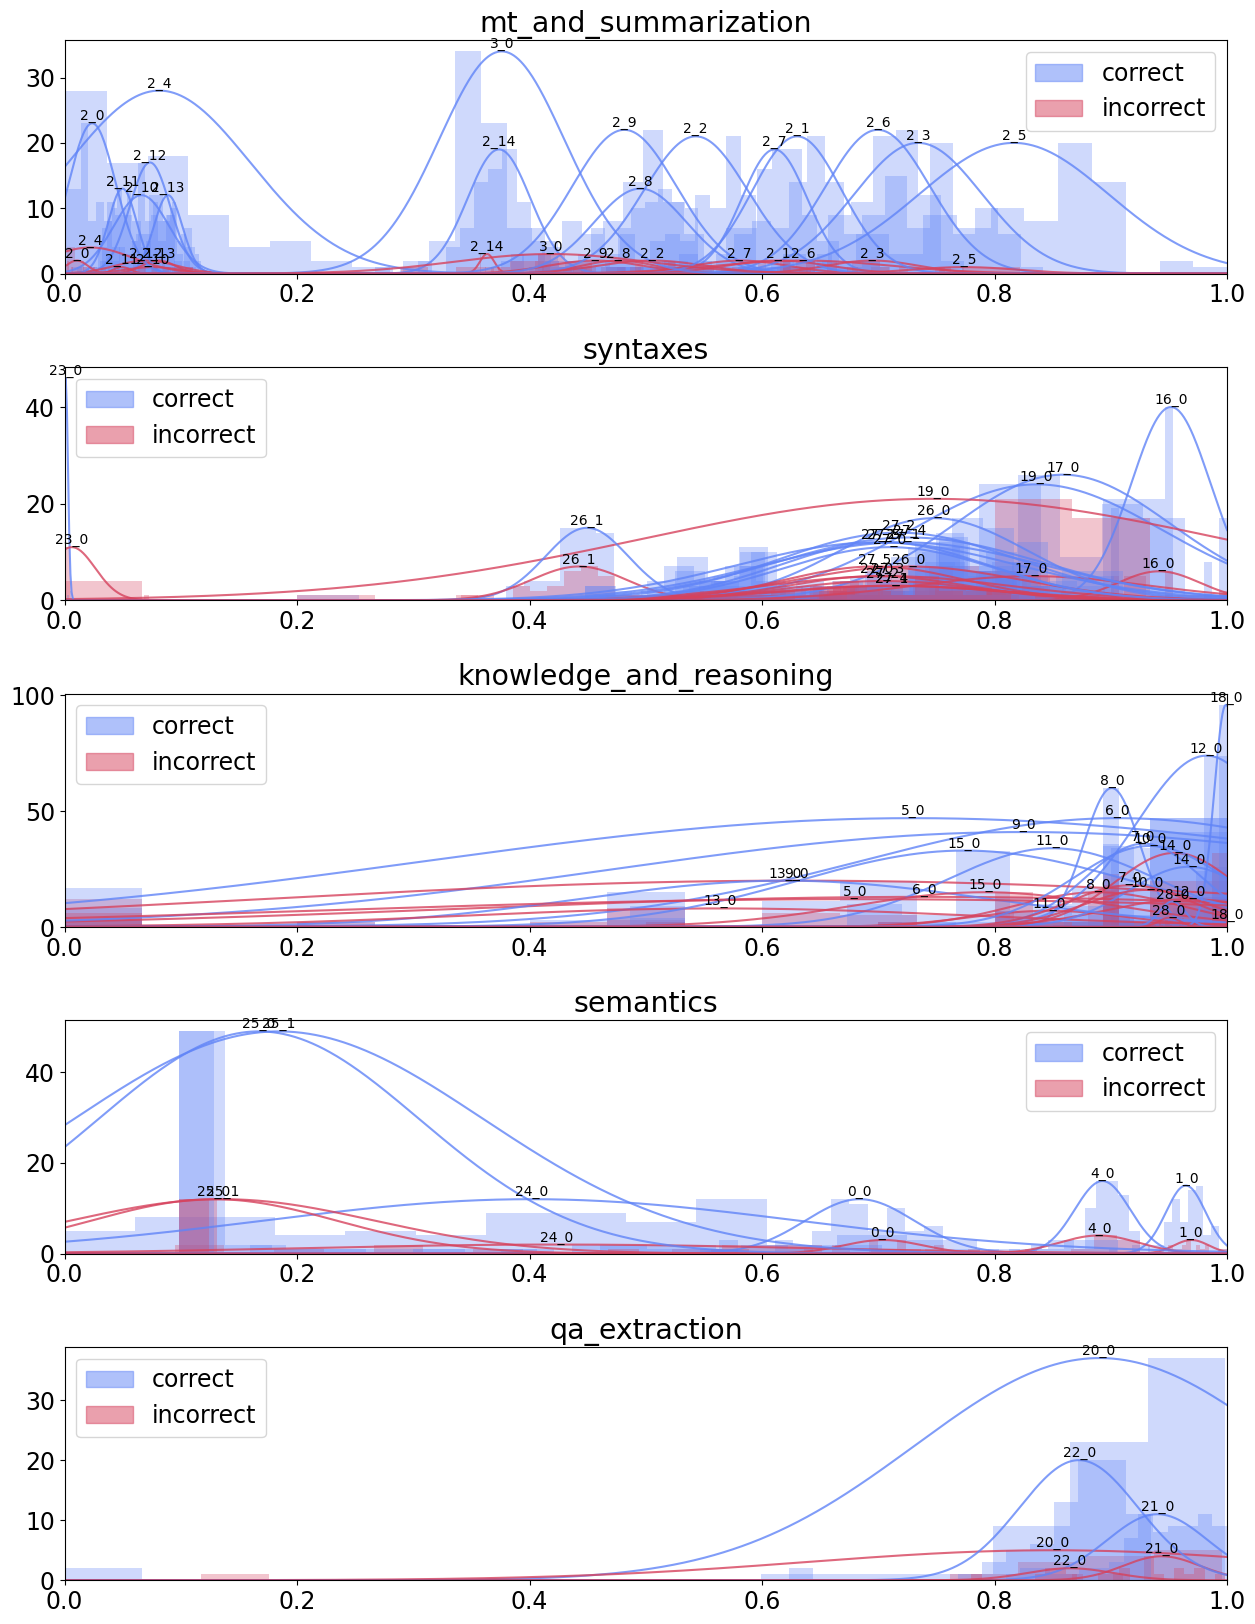

In [6]:
# propmt_sentence_type
characteristics_column = 2
task_group_histogram_data = {}
for tt in task_types:
    taskdf = all_tasktype_df[tt].drop(columns=['id'])
    cols = list(taskdf.columns)
    
    group_tasks_histogram_data = {}
    for i in range(0, len(cols), 4):
        chunk = cols[i:i+4]
        label_scores = {}
        for group_name, group_df in taskdf.groupby(chunk[characteristics_column]):
            label_scores[group_name] = group_df[chunk[-1]].tolist()
        
        task_code = chunk[0].split("-")[0]
        group_tasks_histogram_data[task_code] = label_scores

    all_nums = collect_all_numbers(group_tasks_histogram_data)
    min_val = min(all_nums)
    max_val = max(all_nums)
    task_group_histogram_data[tt] = normalize_nested_dict(group_tasks_histogram_data, min_val, max_val)

# print(json.dumps(task_group_histogram_data, indent=4))
# Plot all as overlapping histograms
colors = {
    "correct" : '#6084f7',
    "incorrect" : '#d6425d',
}

fig, axes = plt.subplots(len(all_tasktype_df.keys()), 1, figsize=(15, 4 * len(all_tasktype_df.keys())))
plt.subplots_adjust(hspace=0.4)  # Increase for more gap
# fig.xlim(0, 1)

for ax, (group_name, group_hist_data) in zip(axes, task_group_histogram_data.items()):
    ax.set_xlim(0, 1)
    ax.set_title(group_name)
    for qdi, classifications in group_hist_data.items():
        for label, score_list in classifications.items():
            counts, bin_edges, _ = ax.hist(score_list, bins=15, alpha=0.3, label=f'Data {i}', color=colors[label])
            
            mu, std = np.mean(score_list), np.std(score_list)
            if std == 0:
                std = 1e-6
            x = np.linspace(0, 1, 1000)
            p = norm.pdf(x, mu, std)
            p_max = np.max(p)
            
            if p_max == 0:
                scale = 1  # or skip plotting the curve
            else:
                scale = max(counts) / p_max

            # Get the current color used for the histogram
            ax.plot(x, p * scale, color=colors[label], alpha=0.8)

            peak_x = x[np.argmax(p)]
            peak_y = max(p) * scale
            ax.text(peak_x, peak_y, qdi, ha='center', va='bottom', fontsize=10)

            legend_patches = [mpatches.Patch(color=col, label=label, alpha=0.5) for label, col in colors.items()]
            ax.legend(handles=legend_patches)
    # break


In [ ]:
# propmt_sentence_type
characteristics_column = 1
tg_correlation_df = []
for tt in task_types:
    taskdf = all_tasktype_df[tt].drop(columns=['id'])
    cols = list(taskdf.columns)

    tg_correlation_data = []
    for i in range(0, len(cols), 4):
        chunk = cols[i:i+4]
        
        correlation = taskdf[chunk[characteristics_column]].corr(taskdf[chunk[-1]])
        task_name = "-".join(chunk[-1].split("-")[:-2])
        tg_correlation_data.append(correlation)

    tg_correlation_df.append({
        "Task Group": tt,
        "Corr. Avg": format(round(np.mean(tg_correlation_data), 2), ".2f"),
        "Corr. Std": format(round(np.std(tg_correlation_data), 2), ".2f"),
    })
# print(tg_correlation_df)
tg_correlation_df = pd.DataFrame(tg_correlation_df)
tg_correlation_df

,Task Group,Corr. Avg,Corr. Std
0,mt_and_summarization,0.01,0.20
1,syntaxes,0.33,0.30
2,knowledge_and_reasoning,0.06,0.15
3,semantics,0.23,0.13
4,qa_extraction,-0.15,0.05


In [8]:
print(tg_correlation_df.replace('_', r'\\_', regex=True).to_latex(index=False))

\begin{tabular}{lll}
\toprule
Task Group & Corr. Avg & Corr. Std \\
\midrule
mt\_and\_summarization & 0.01 & 0.20 \\
syntaxes & 0.33 & 0.30 \\
knowledge\_and\_reasoning & 0.06 & 0.15 \\
semantics & 0.23 & 0.13 \\
qa\_extraction & -0.15 & 0.05 \\
\bottomrule
\end{tabular}

